In [49]:
# import pandas as pd
# campaign = pd.read_csv('https://raw.githubusercontent.com/byui-cse/cse450-course/master/data/bank.csv')

# import polars as pl
# campaign = pl.read_csv('https://raw.githubusercontent.com/byui-cse/cse450-course/master/data/bank.csv', schema_overrides={'nr.employed': pl.Float64})

In [50]:
import pandas as pd
from sklearn.model_selection import train_test_split

url = "https://raw.githubusercontent.com/byui-cse/cse450-course/master/data/bank.csv"

bank = pd.read_csv(url)

bank.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [51]:

bank = bank.dropna()

bank["y"] = bank["y"].map({"yes": 1, "no": 0})

bank = bank.dropna(subset=["y"])

X = bank.drop(columns=["y"])
y = bank["y"]

X = pd.get_dummies(X, drop_first=False)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [52]:
from sklearn.tree import DecisionTreeClassifier

model = DecisionTreeClassifier(
    max_depth=5,
    min_samples_leaf=10,
    random_state=42
)

model.fit(X_train, y_train)

DecisionTreeClassifier(max_depth=5, min_samples_leaf=10, random_state=42)

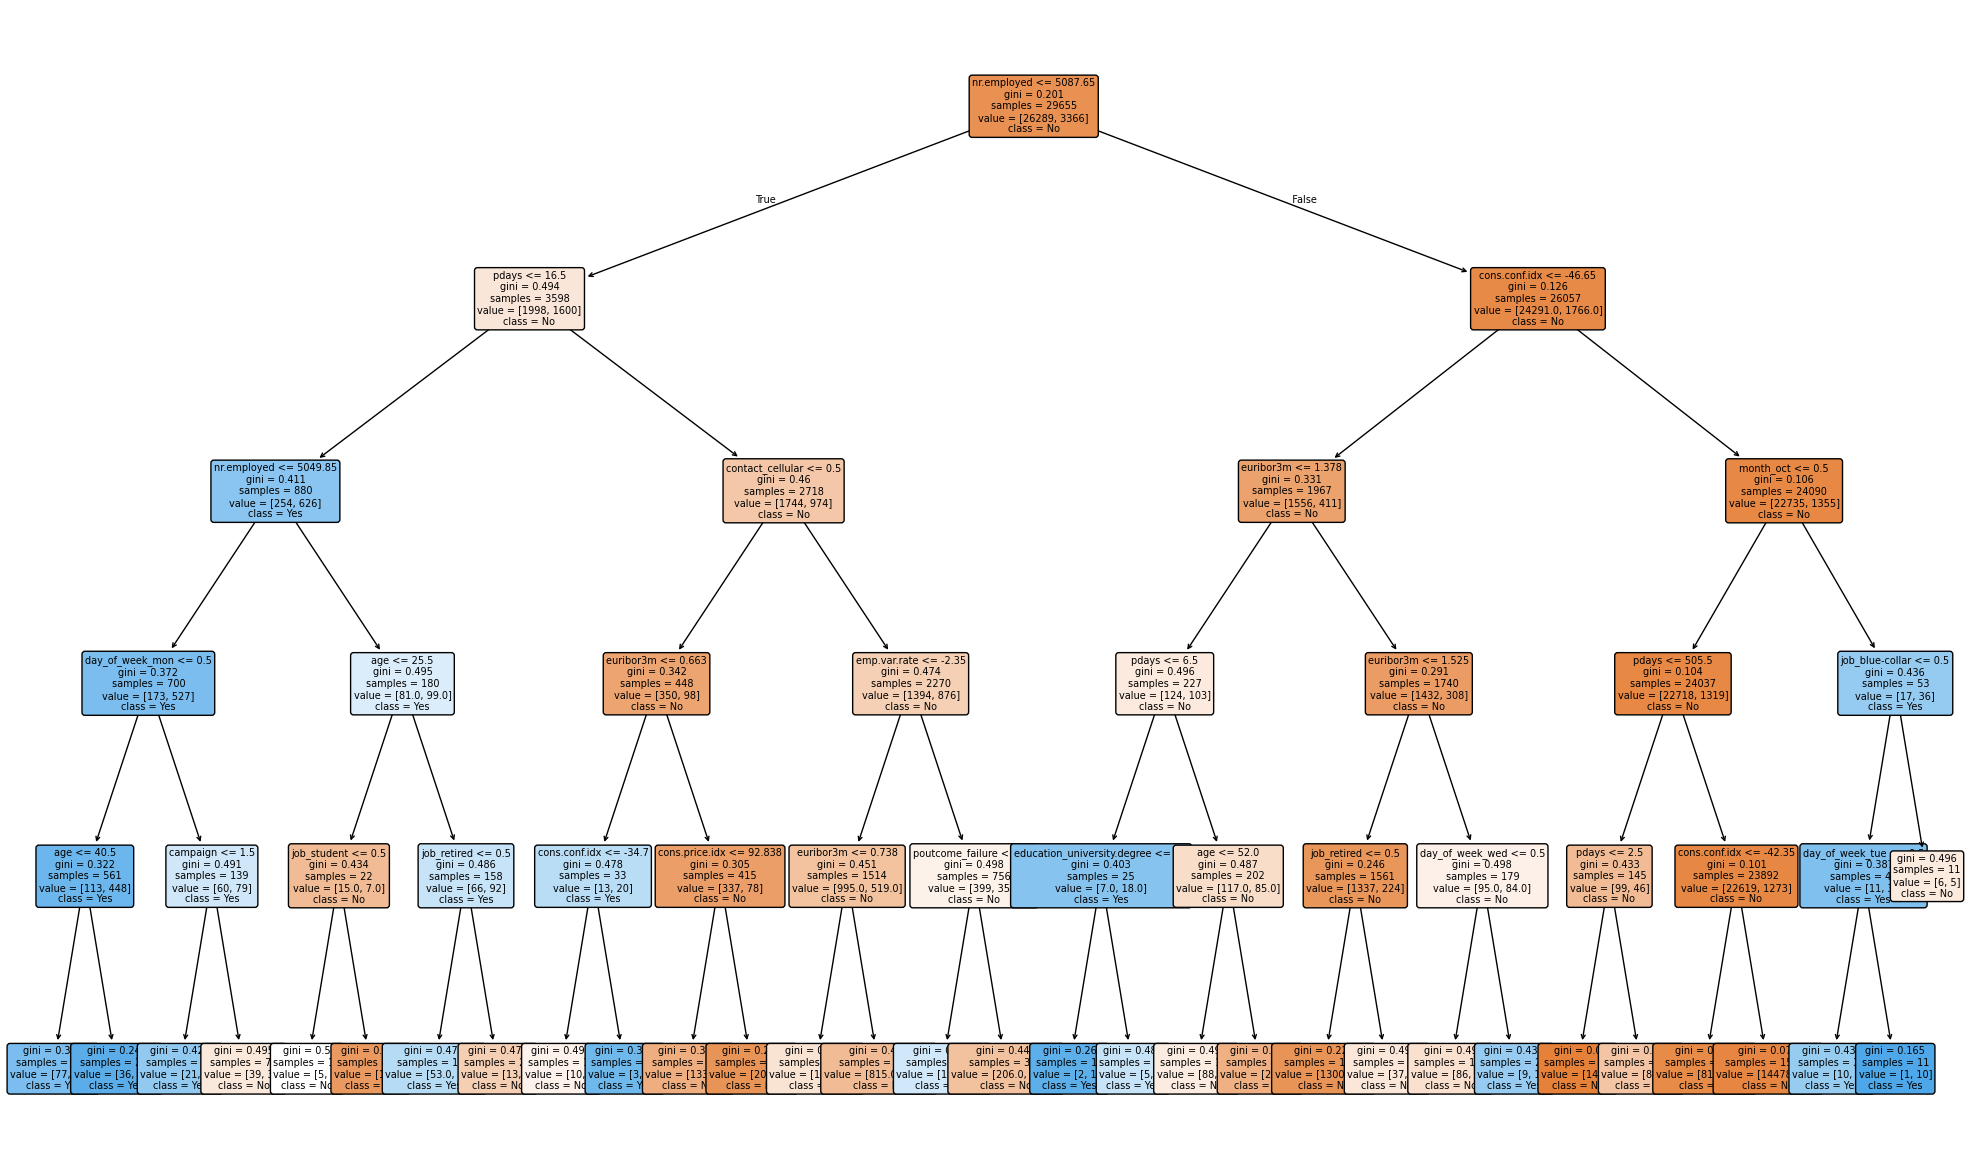

In [53]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

plt.figure(figsize=(25, 15))

plot_tree(
    model,
    feature_names=X.columns,
    class_names=["No", "Yes"],
    filled=True,
    rounded=True,
    fontsize=7
)

plt.show()

In [54]:
from sklearn.metrics import accuracy_score, classification_report

predictions = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, predictions))
print(classification_report(y_test, predictions))

Accuracy: 0.900593471810089
              precision    recall  f1-score   support

           0       0.91      0.98      0.95      6572
           1       0.65      0.26      0.38       842

    accuracy                           0.90      7414
   macro avg       0.78      0.62      0.66      7414
weighted avg       0.88      0.90      0.88      7414



In [55]:
model_balanced = DecisionTreeClassifier(
    max_depth=5,
    min_samples_leaf=10,
    class_weight="balanced",
    random_state=42
)

model_balanced.fit(X_train, y_train)

balanced_predictions = model_balanced.predict(X_test)

print("Accuracy:", accuracy_score(y_test, balanced_predictions))
print(classification_report(y_test, balanced_predictions))

Accuracy: 0.8461019692473698
              precision    recall  f1-score   support

           0       0.95      0.87      0.91      6572
           1       0.39      0.63      0.48       842

    accuracy                           0.85      7414
   macro avg       0.67      0.75      0.69      7414
weighted avg       0.88      0.85      0.86      7414

